# Selected FX forecast: training and calibration

This notebook analyzes the fixed causal gate on complete chronological validation and the completed cloud training/calibration run. It recomputes validation aggregates from saved predictions when the private artifacts are available. It does not train locally or evaluate 2026 targets. Data and checkpoints remain ignored.

In [1]:
from pathlib import Path
import os, json, hashlib, math, ast, statistics
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists()
os.chdir(ROOT)
def read(path): return json.loads(Path(path).read_bytes())
def digest(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
summary = read("docs/gated-training-calibration.json")
policy = read("docs/gated-forecast-policy.json")
assert digest("docs/gated-forecast-policy.json") == summary["policy_sha256"]
assert summary["test_accessed"] is False
FIGURES = ROOT / "docs/figures"
FIGURES.mkdir(exist_ok=True)
def show(fig, name):
    fig.tight_layout()
    path = FIGURES / (name + ".png")
    fig.savefig(path, dpi=150)
    plt.close(fig)
    display(Image(filename=str(path)))
print("Selected policy:", policy["gate_threshold"], policy["gate_multiplier"], policy["gate_comparison"])


Selected policy: 1.2 2 strict_greater_than


## Fixed prediction and interval rules

The learned mean uses 22 causal features, training-only standardization and Ridge alpha 10,000 without an intercept. It returns twice the mean prediction only when the current volatility ratio is strictly greater than 1.2; otherwise it returns zero. Calibration uses a separate 2025 cohort and a fixed 90% residual order statistic.

In [2]:
def number(value):
    if isinstance(value, bool): raise ValueError("Finite numeric scalar required")
    value = float(value)
    if not math.isfinite(value): raise ValueError("Finite numeric scalar required")
    return value

def gate_predictions(predictions, ratios, threshold, multiplier):
    """No targets or future information enter this prediction transform."""
    if (
        type(threshold) not in (int, float)
        or threshold not in (1.0, 1.2)
        or type(multiplier) is not int
        or multiplier not in (1, 2)
    ):
        raise ValueError("Declared fixed threshold and multiplier required")
    if len(predictions) != len(ratios):
        raise ValueError("Aligned predictions and causal ratios required")
    values = []
    for prediction, ratio in zip(predictions, ratios):
        prediction, ratio = number(prediction), number(ratio)
        if ratio < 0:
            raise ValueError("Nonnegative volatility ratio required")
        values.append(number(multiplier * prediction) if ratio > threshold else 0.0)
    return values

def quantile90(values):
    """Fixed finite-sample order statistic; no interpolation or width selection."""
    if not values:
        raise ValueError("Nonempty interval calibration support required")
    values = sorted(number(value) for value in values)
    if values[0] < 0:
        raise ValueError("Nonnegative calibration residuals required")
    rank = math.ceil((len(values) + 1) * 0.9)
    if rank > len(values):
        raise ValueError("Insufficient interval calibration support")
    return values[rank - 1]

## Complete chronological validation

All 2,961 eligible asset decisions from 2021–2024 are included. Zero return and the same learned mean without the gate are reference controls. Repeated validation selection and a small improvement limit the strength of the result; the descriptive month-bootstrap interval crosses zero.

,model,rows,RMSE
0,Zero return,2961,0.003914
1,Ungated mean,2961,0.003911
2,Selected gate,2961,0.003906


model,Selected gate,Ungated mean,Zero return
year,,,
2021,0.003500,0.003503,0.003510
2022,0.004856,0.004867,0.004874
2023,0.004003,0.004001,0.004001
2024,0.003041,0.003047,0.003042


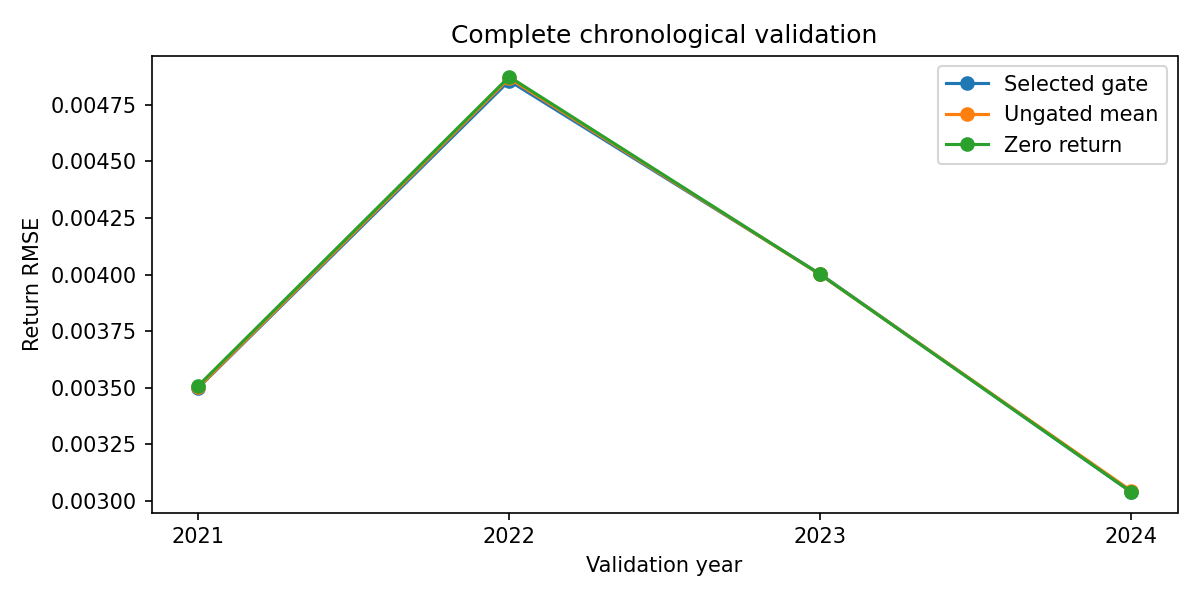

In [3]:
labels = {"zero": "Zero return", "linear_10000": "Ungated mean", "gate_1.2_2": "Selected gate"}
rows = [{"model": labels[x["name"]], "rows": x["validation"]["n"], "RMSE": x["validation"]["rmse"]} for x in summary["validation"]]
validation = pd.DataFrame(rows)
assert set(validation.rows) == {2961}
display(validation)
folds = pd.DataFrame([{"model": labels[x["name"]], **fold} for x in summary["validation"] for fold in x["folds"]])
display(folds.pivot(index="year", columns="model", values="rmse"))
fig, ax = plt.subplots(figsize=(8, 4))
for model, group in folds.groupby("model"):
    ax.plot(group.year, group.rmse, marker="o", label=model)
ax.set(xlabel="Validation year", ylabel="Return RMSE", title="Complete chronological validation")
ax.set_xticks(sorted(folds.year.unique()))
ax.legend()
show(fig, "selected_gate_validation")


## Recompute the saved validation predictions

This optional replay uses the complete private prediction files from the actual development run. It checks row identities and recomputes pooled and yearly RMSE, without loading or fitting a model. Public readers can inspect the executed output and the aggregate table above.

In [4]:
private = ROOT / "data/interim/volatility-gate-v6/results"
if all((private / (name + "-private-predictions.json")).exists() for name in labels):
    identity = None
    replay = []
    for run in summary["validation"]:
        records = read(private / (run["name"] + "-private-predictions.json"))
        keys = [(row["asset"], row["date"]) for row in records]
        assert len(records) == len(set(keys)) == 2961
        if identity is None: identity = keys
        assert keys == identity
        def rmse(items):
            return math.sqrt(math.fsum((number(x["target"]) - number(x["prediction"])) ** 2 for x in items) / len(items))
        measured = rmse(records)
        assert abs(measured - run["validation"]["rmse"]) < 1e-14
        for fold in run["folds"]:
            subset = [x for x in records if int(x["date"][:4]) == fold["year"]]
            assert len(subset) == fold["n"]
            assert abs(rmse(subset) - fold["rmse"]) < 1e-14
        replay.append({"model": labels[run["name"]], "complete_rows": len(records), "recomputed_RMSE": measured})
    display(pd.DataFrame(replay))
else:
    print("Private prediction files are required for numerical replay; no new scores computed.")


,model,complete_rows,recomputed_RMSE
0,Zero return,2961,0.003914
1,Ungated mean,2961,0.003911
2,Selected gate,2961,0.003906


## Final mean fit and separate calibration

The final fit used every eligible matured training decision through 2024. All 741 eligible 2025 decisions calibrated intervals after the mean weights were frozen. The receipts bind the saved states and both checkpoints.

In [5]:
training = pd.DataFrame.from_dict(summary["training"], orient="index")
calibration = pd.DataFrame.from_dict(summary["calibration"], orient="index")
assert len(training) == len(calibration) == 3
assert training.rows.sum() == 5799 and set(training.rows) == {1933}
assert calibration.rows.sum() == 741 and set(calibration.rows) == {247}
assert set(training.last_target_maturity) == {"2024-12-31"}
assert set(calibration.first_decision) == {"2025-01-02"}
assert set(calibration.last_target_maturity) == {"2025-12-31"}
assert summary["mean_save_reload_max_difference"] == 0
assert summary["mean_refitted_for_calibration"] is False
display(training)
display(calibration)
print("Mean save/reload difference:", summary["mean_save_reload_max_difference"])
print("Mean refitted for calibration:", summary["mean_refitted_for_calibration"])


,rows,first_decision,last_decision,last_target_maturity
FXEURCAD,1933,2017-03-29,2024-12-27,2024-12-31
FXGBPCAD,1933,2017-03-29,2024-12-27,2024-12-31
FXAUDCAD,1933,2017-03-29,2024-12-27,2024-12-31


,rows,first_decision,last_decision,last_target_maturity,normalized_quantile
FXEURCAD,247,2025-01-02,2025-12-29,2025-12-31,1.617421
FXGBPCAD,247,2025-01-02,2025-12-29,2025-12-31,1.804818
FXAUDCAD,247,2025-01-02,2025-12-29,2025-12-31,1.581997


Mean save/reload difference: 0.0
Mean refitted for calibration: False


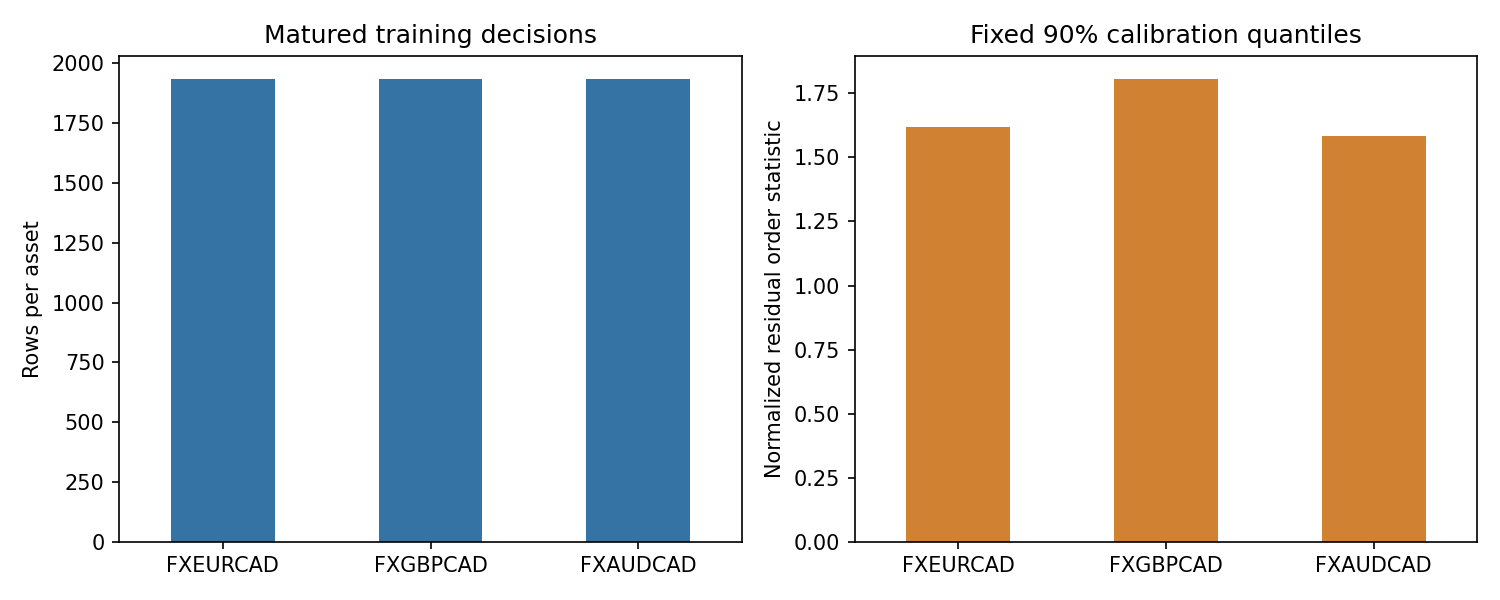

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
training.rows.plot.bar(ax=axes[0], color="#3573a5", rot=0)
axes[0].set(title="Matured training decisions", ylabel="Rows per asset")
calibration.normalized_quantile.plot.bar(ax=axes[1], color="#d18132", rot=0)
axes[1].set(title="Fixed 90% calibration quantiles", ylabel="Normalized residual order statistic")
show(fig, "selected_gate_training_calibration")


## Fresh-artifact reproduction

The public CLI was exercised in a separate cloud run with the fixed source snapshots and no original model checkpoint mounted. Three fresh fits reproduced the selected numerical model states exactly. The same run produced all 747 pre-2026 forecasts and calibrated all 741 eligible decisions. This verifies the workflow; it computes no test accuracy.

In [7]:
import shlex
commands = [
    ["python", "-m", "src.gated_workflow", "train", "--snapshot", "data/my-training-snapshot.json", "--policy", "docs/gated-forecast-policy.json", "--output", "models/my-run"],
    ["python", "-m", "src.gated_workflow", "calibrate", "--run", "models/my-run", "--parent", "data/my-development-parent.json", "--policy", "docs/gated-forecast-policy.json", "--freeze-sha256", "SHA256_OF_MY_MEAN_FREEZE", "--output", "models/my-calibration"],
]
for command in commands: print(shlex.join(command))
print("Use the exact pinned snapshots and a fresh output directory. These commands are displayed, not executed in this analysis notebook.")


python -m src.gated_workflow train --snapshot data/my-training-snapshot.json --policy docs/gated-forecast-policy.json --output models/my-run
python -m src.gated_workflow calibrate --run models/my-run --parent data/my-development-parent.json --policy docs/gated-forecast-policy.json --freeze-sha256 SHA256_OF_MY_MEAN_FREEZE --output models/my-calibration
Use the exact pinned snapshots and a fresh output directory. These commands are displayed, not executed in this analysis notebook.


In [8]:
integration = summary["coldstart_integration"]
assert integration["actual_fresh_mean_fits"] == 3
assert integration["matured_training_rows"] == 5799
assert integration["pre2026_mean_forecast_rows"] == 747
assert integration["calibration_rows"] == 741
assert integration["reference_numerical_state_equal"] is True
assert integration["mean_final_reload_max_delta"] == 0
assert integration["original_model_artifacts_mounted"] is False
assert integration["test_accessed"] is False and integration["accuracy_evaluated"] is False
display(pd.DataFrame([{k: integration[k] for k in ["actual_fresh_mean_fits", "matured_training_rows", "pre2026_mean_forecast_rows", "calibration_rows", "mean_final_reload_max_delta"]}]))
print("Completed cloud proof SHA256:", integration["proof_sha256"])
print("Numerical model states match the selected reference:", integration["reference_numerical_state_equal"])
print("Runtime:", integration["environment"])


,actual_fresh_mean_fits,matured_training_rows,pre2026_mean_forecast_rows,calibration_rows,mean_final_reload_max_delta
0,3,5799,747,741,0.0


Completed cloud proof SHA256: 28ef518d9166b28edb8533941985c10cfef596faf77045218f01883f4cdf4dc4
Numerical model states match the selected reference: True
Runtime: {'python': '3.13.15', 'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'joblib': '1.4.2', 'threadpoolctl': '3.6.0'}


Bank of Canada reference rates are not executable quotes. Serial dependence and current-vintage data limit interval coverage claims. Validation RMSE alone does not establish a profitable strategy. Retrospective evaluation is kept separate from model selection.